In [1]:
import numpy as np
import demes
import h2py
import pickle

In [16]:
def bootstrap_naive(rep):
    input_data = dict()
    for c in range(1, 23):
        filename = f"outputs/rep_{rep}_chr_{c}_naive.pkl"
        with open(filename, "rb") as fin:
            chrom_data = pickle.load(fin)
        for key in chrom_data:
            if chrom_data[key]["denoms"][-1] > 10:
                input_data[key] = chrom_data[key]
    n_sites = 0
    for key in input_data:
        n_sites += input_data[key]["denoms"][-1]
    print(n_sites)
    return h2py.parsing.bootstrap_data(input_data)


def bootstrap_adj(rep):
    input_data = dict()
    for c in range(1, 23):
        filename = f"outputs/rep_{rep}_chr_{c}_adj.pkl"
        with open(filename, "rb") as fin:
            chrom_data = pickle.load(fin)
        for key in chrom_data:
            if chrom_data[key]["denoms"][-1] > 10:
                input_data[key] = chrom_data[key]
    u_bar, n_sites = h2py.parsing.compute_avg_u(input_data)
    print(u_bar, n_sites)
    fac = u_bar ** 2
    for key in input_data:
        for i in range(len(input_data[key]["sums"]) - 1):
            input_data[key]["sums"][i] *= fac
    return h2py.parsing.bootstrap_data(input_data)

In [3]:
graph_file = "deployment/graph.yaml"
u = 1.1631e-8
bins = np.logspace(-6, -2, 17)
model = h2py.H2stats.from_demes(graph_file, u=u, r_bins=bins, sampled_demes=["pop1", "pop2"])

In [5]:
#data_naive = bootstrap_naive(0)
#x = h2py.plotting.plot_h2_curves_comp(model, data_naive["means"], data_naive["varcovs"], r_bins=data_naive["bins"], fig_size=(6, 2.5), )

1.1631246767878291e-08 2661154663.0


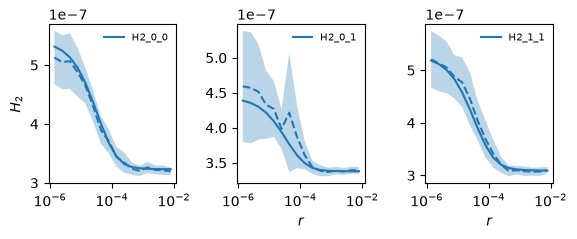

In [17]:
data_adj = bootstrap_adj(0)
x = h2py.plotting.plot_h2_curves_comp(model, data_adj["means"], data_adj["varcovs"], r_bins=data_adj["bins"], fig_size=(6, 2.5), )

In [ ]:
def bootstrap_naive(rep):
    input_data = dict()
    for c in range(1, 23):
        filename = f"outputs/rep_{rep}_chr_{c}_naive.pkl"
        with open(filename, "rb") as fin:
            chrom_data = pickle.load(fin)
        for key in chrom_data:
            if chrom_data[key]["denoms"][-1] > 10:
                input_data[key] = chrom_data[key]
    n_sites = 0
    for key in input_data:
        n_sites += input_data[key]["denoms"][-1]
    print(n_sites)
    return h2py.parsing.bootstrap_data(input_data)


def bootstrap_adj():
    input_data = dict()
    for rep in range(10):
        for c in range(1, 23):
            filename = f"outputs/rep_{rep}_chr_{c}_adj.pkl"
            with open(filename, "rb") as fin:
                chrom_data = pickle.load(fin)
            for key in chrom_data:
                if chrom_data[key]["denoms"][-1] > 10:
                    input_data[key] = chrom_data[key]
    u_bar, n_sites = h2py.parsing.compute_avg_u(input_data)
    print(u_bar, n_sites)
    fac = u_bar ** 2
    for key in input_data:
        for i in range(len(input_data[key]["sums"]) - 1):
            input_data[key]["sums"][i] *= fac
    return h2py.parsing.get_means_across_regions(input_data)  #h2py.parsing.bootstrap_data(input_data)

In [ ]:
data_adj = bootstrap_adj()
data_bins = h2py.parsing._get_bin_tuples(bins)
x = h2py.plotting.plot_h2_curves_comp(model, data_adj, None, plot_errs=False, r_bins=data_bins, fig_size=(6, 2.5), )